<a href="https://colab.research.google.com/github/Prayansh-builds/ai-colorist/blob/main/ai_colorist_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (1600, 1200, 3) | Min: 0.0 | Max: 1.0


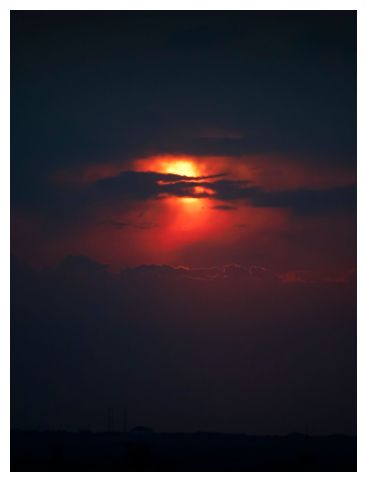

In [9]:
# Connect Google Drive so Colab can see your photos
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import cv2
import matplotlib.pyplot as plt

# Path to one of your test photos
path = "/content/drive/MyDrive/ai-colorist/test_images/photo1.jpg"

# Load the photo
img_bgr = cv2.imread(path)
if img_bgr is None:
    raise FileNotFoundError("Photo not found. Check the folder and file name.")

# OpenCV loads colours as Blue-Green-Red, so flip to Red-Green-Blue
# Then divide by 255 so every value sits between 0 and 1
img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

# Print the photo's shape and brightest/darkest values
print("Shape:", img.shape, "| Min:", img.min(), "| Max:", img.max())

# Show it
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")
plt.show()


In [10]:
# Connect Drive again (Colab forgets it when it disconnects)
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import cv2
import os
import matplotlib.pyplot as plt

# Change to "test_images_1600" if you made the resized copies
FOLDER = "/content/drive/MyDrive/ai-colorist/test_images"

# List every photo in the folder
files = [f for f in sorted(os.listdir(FOLDER))
         if f.lower().endswith((".jpg", ".jpeg", ".png"))]
print(len(files), "photos found")

def load_image(name):
    bgr = cv2.imread(os.path.join(FOLDER, name))
    if bgr is None:
        raise FileNotFoundError("Cannot open " + name)
    # Flip to RGB and scale every value to the 0-1 range
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

def show_many(images, titles):
    # Show several images in one row
    plt.figure(figsize=(16, 4))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(np.clip(im, 0, 1))
        plt.title(t)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
22 photos found


In [11]:
# ---------- Helpers ----------
def srgb_to_linear(x):
    # Photos store brightness in a squashed way. This undoes it,
    # so exposure maths behaves like real light.
    return np.where(x <= 0.04045, x / 12.92, ((x + 0.055) / 1.055) ** 2.4)

def linear_to_srgb(x):
    # Squash it back so it looks right on screen
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, x * 12.92, 1.055 * (x ** (1 / 2.4)) - 0.055)

def luma(img):
    # How bright each pixel feels to the eye (green counts the most)
    return (0.2126 * img[..., 0] + 0.7152 * img[..., 1] + 0.0722 * img[..., 2])[..., None]

# ---------- The dials ----------
def exposure(img, stops):
    # +1 stop = twice the light
    lin = srgb_to_linear(img) * (2.0 ** stops)
    return linear_to_srgb(lin)

def contrast(img, amount):
    if amount >= 0:
        s = img * img * (3 - 2 * img)       # a gentle S-curve
        out = img + amount * (s - img)       # blend toward the S-curve
    else:
        out = (img - 0.5) * (1 + amount) + 0.5   # flatten toward grey
    return np.clip(out, 0, 1)

def saturation(img, amount):
    gray = luma(img)                         # the colourless version
    return np.clip(gray + (img - gray) * (1 + amount), 0, 1)

def temperature(img, amount):
    out = img.copy()
    out[..., 0] *= 1 + 0.15 * amount         # more red = warmer
    out[..., 2] *= 1 - 0.15 * amount         # less blue = warmer
    return np.clip(out, 0, 1)

def tint(img, amount):
    out = img.copy()
    out[..., 1] *= 1 - 0.15 * amount         # less green = more magenta
    return np.clip(out, 0, 1)

def shadows(img, amount):
    weight = (1 - luma(img)) ** 2            # strong in dark areas, weak in bright
    return np.clip(img * (1 + amount * weight), 0, 1)

def highlights(img, amount):
    weight = luma(img) ** 2                  # strong in bright areas, weak in dark
    return np.clip(img * (1 + amount * weight), 0, 1)

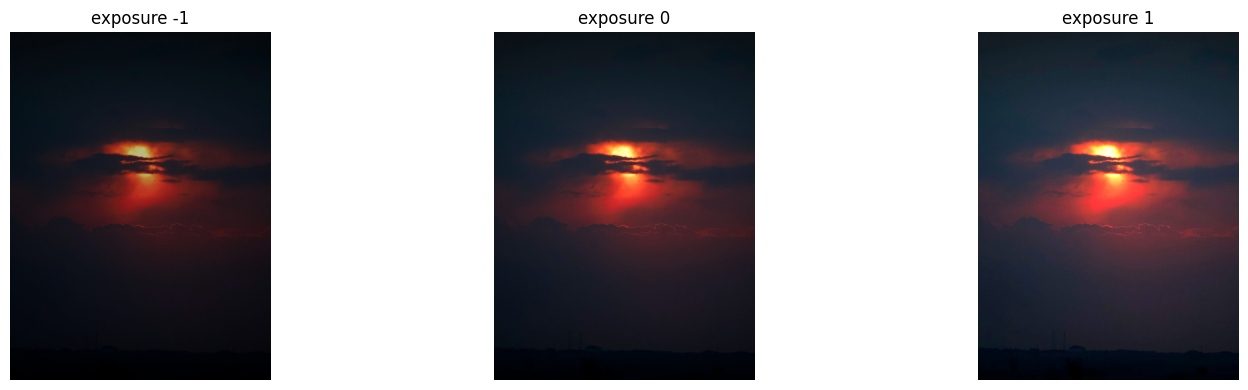

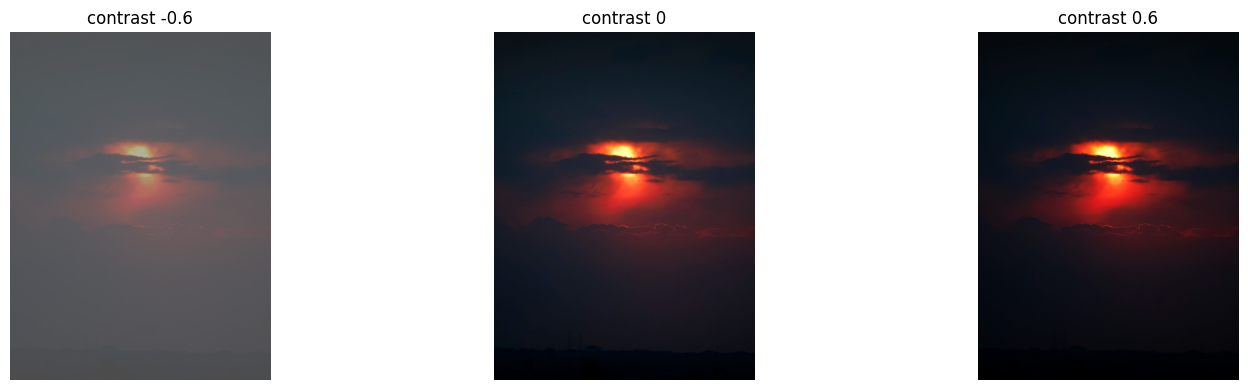

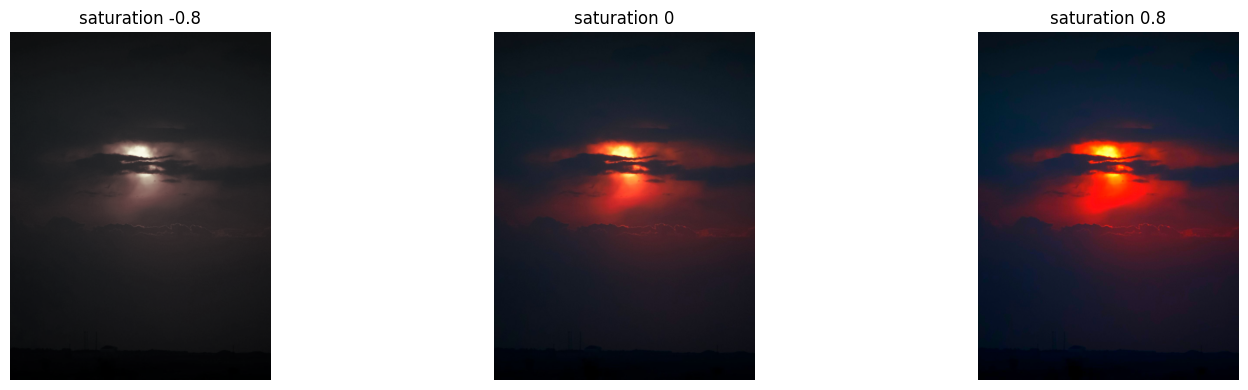

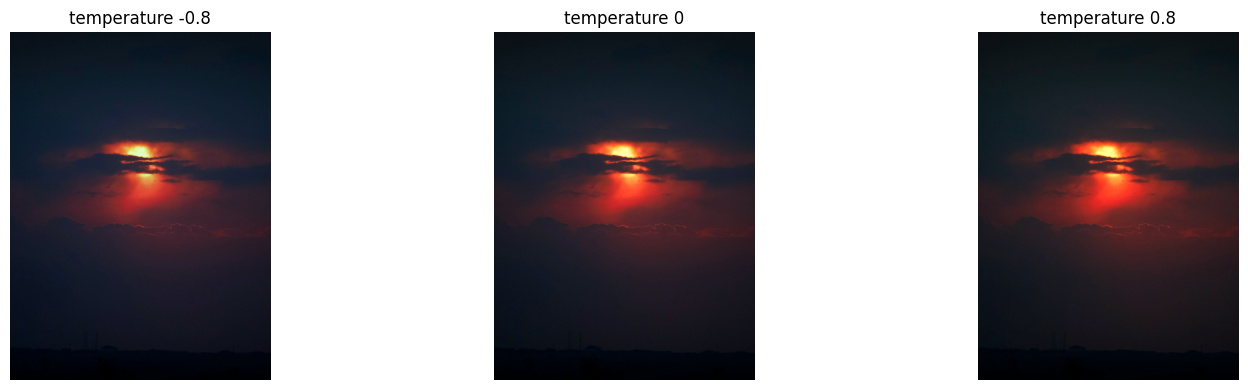

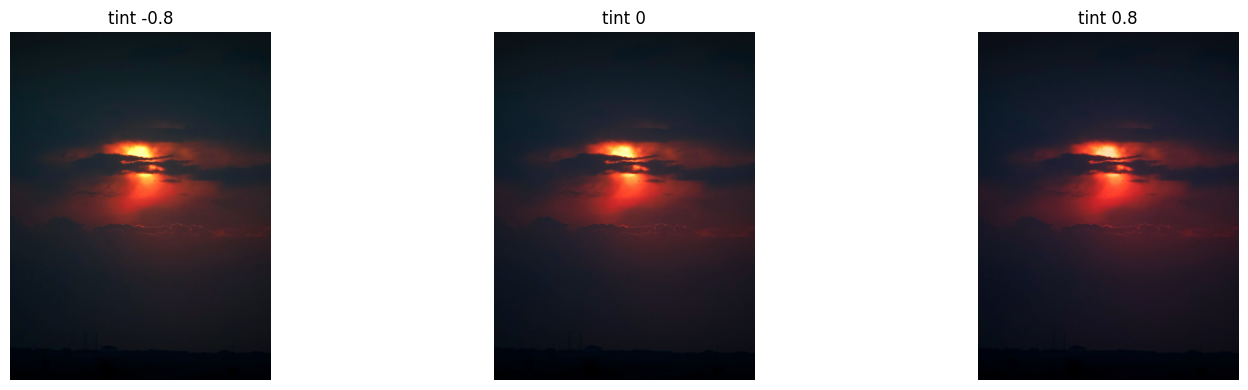

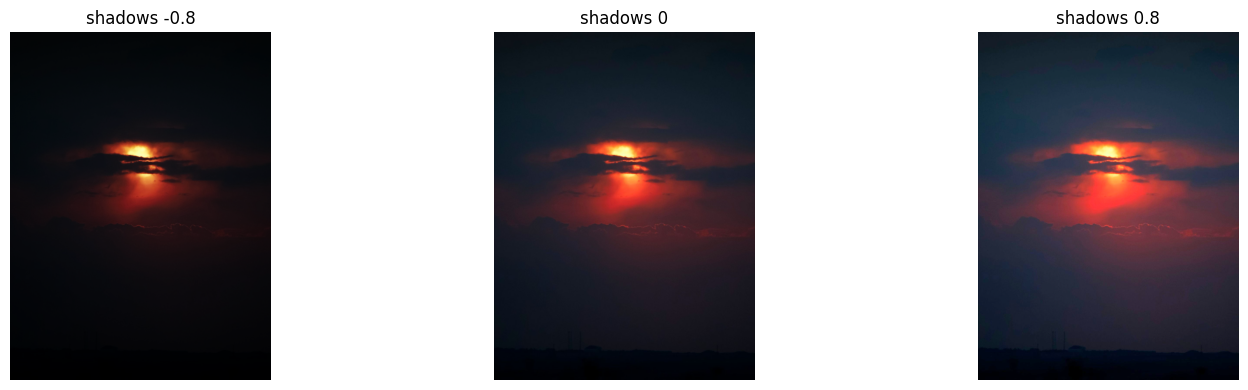

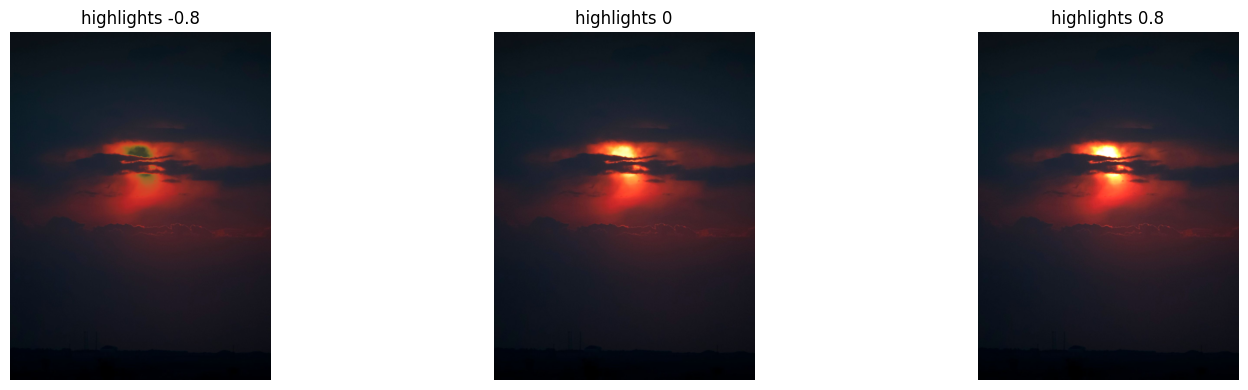

In [12]:
img = load_image(files[0])      # try files[1], files[2], ... for other photos

def strip(dial, values):
    # Show the same photo at three dial settings
    show_many([dial(img, v) for v in values],
              [dial.__name__ + " " + str(v) for v in values])

strip(exposure,    [-1, 0, 1])
strip(contrast,    [-0.6, 0, 0.6])
strip(saturation,  [-0.8, 0, 0.8])
strip(temperature, [-0.8, 0, 0.8])
strip(tint,        [-0.8, 0, 0.8])
strip(shadows,     [-0.8, 0, 0.8])
strip(highlights,  [-0.8, 0, 0.8])

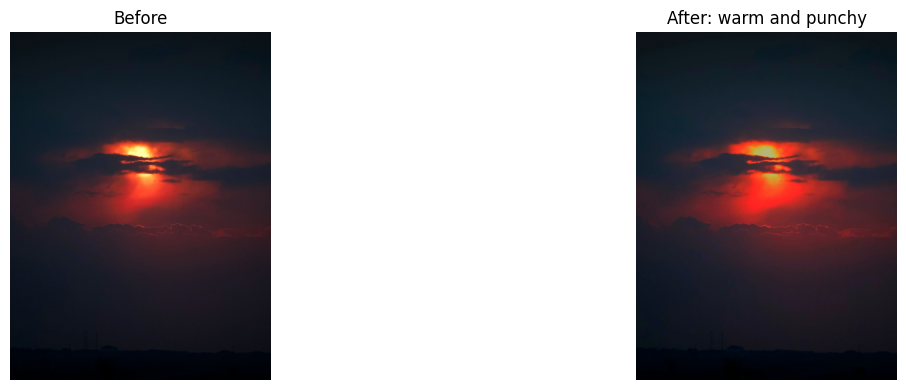

In [13]:
def grade(img, exposure_stops=0, contrast_amt=0, saturation_amt=0,
          temp=0, tint_amt=0, shadows_amt=0, highlights_amt=0):
    # Keep every dial inside its safe range
    clamp = lambda v, lo, hi: float(np.clip(v, lo, hi))

    out = exposure(img, clamp(exposure_stops, -3, 3))
    out = temperature(out, clamp(temp, -1, 1))
    out = tint(out, clamp(tint_amt, -1, 1))
    out = contrast(out, clamp(contrast_amt, -1, 1))
    out = shadows(out, clamp(shadows_amt, -1, 1))
    out = highlights(out, clamp(highlights_amt, -1, 1))
    out = saturation(out, clamp(saturation_amt, -1, 1))
    return out

# A quick "warm and punchy" look
warm = grade(img, exposure_stops=0.2, contrast_amt=0.25, saturation_amt=0.1,
             temp=0.4, shadows_amt=0.3, highlights_amt=-0.3)

show_many([img, warm], ["Before", "After: warm and punchy"])

In [14]:
def split_view(before, after, split):
    # Left of the line shows the original, right of it shows the graded photo
    h, w = before.shape[:2]
    x = int(w * split)
    out = after.copy()
    out[:, :x] = before[:, :x]
    # Draw a thin white divider line
    line = max(1, w // 400)
    out[:, max(0, x - line):x + line] = 1.0
    return out

In [15]:
# Makes a small preview copy of a photo, so everything runs fast
def small(img, max_side=800):
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1:
        return cv2.resize(img, (int(w * scale), int(h * scale)),
                          interpolation=cv2.INTER_AREA)
    return img

In [16]:
import ipywidgets as widgets

PHOTO_INDEX = 0                          # which photo to work on (0 = first one)
img = small(load_image(files[PHOTO_INDEX]))

last = {}                                # remembers your latest slider values

def S(label, lo, hi):
    # Builds one slider. It updates when you let go, which keeps it fast
    return widgets.FloatSlider(
        value=0, min=lo, max=hi, step=0.05, description=label,
        continuous_update=False,
        style={"description_width": "80px"},
        layout=widgets.Layout(width="450px"))

@widgets.interact(
    split=widgets.FloatSlider(value=0.5, min=0, max=1, step=0.01,
                              description="Split", continuous_update=False,
                              style={"description_width": "80px"},
                              layout=widgets.Layout(width="450px")),
    exposure_stops=S("Exposure", -3, 3),
    contrast_amt=S("Contrast", -1, 1),
    saturation_amt=S("Saturation", -1, 1),
    temp=S("Temperature", -1, 1),
    tint_amt=S("Tint", -1, 1),
    shadows_amt=S("Shadows", -1, 1),
    highlights_amt=S("Highlights", -1, 1))
def viewer(split, exposure_stops, contrast_amt, saturation_amt,
           temp, tint_amt, shadows_amt, highlights_amt):
    values = dict(exposure_stops=exposure_stops, contrast_amt=contrast_amt,
                  saturation_amt=saturation_amt, temp=temp, tint_amt=tint_amt,
                  shadows_amt=shadows_amt, highlights_amt=highlights_amt)
    last.clear()
    last.update(values)                  # save the settings for the export step

    graded = grade(img, **values)
    plt.figure(figsize=(9, 6))
    plt.imshow(np.clip(split_view(img, graded, split), 0, 1))
    plt.axis("off")
    plt.show()

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='Split', layout=Layout(width…

In [17]:
out_dir = "/content/drive/MyDrive/ai-colorist/outputs"
os.makedirs(out_dir, exist_ok=True)

full = load_image(files[PHOTO_INDEX])        # the original, full-size photo
graded_full = grade(full, **last)            # the same slider settings

# Convert back from 0-1 numbers to a normal photo file
rgb8 = (np.clip(graded_full, 0, 1) * 255).astype(np.uint8)
bgr = cv2.cvtColor(rgb8, cv2.COLOR_RGB2BGR)
save_path = os.path.join(out_dir, "graded_" + files[PHOTO_INDEX])
cv2.imwrite(save_path, bgr, [cv2.IMWRITE_JPEG_QUALITY, 95])
print("Saved:", save_path)
print("Settings used:", last)

Saved: /content/drive/MyDrive/ai-colorist/outputs/graded_photo1.jpg
Settings used: {'exposure_stops': 0.0, 'contrast_amt': 0.0, 'saturation_amt': 0.0, 'temp': 0.0, 'tint_amt': 0.0, 'shadows_amt': 0.0, 'highlights_amt': 0.0}


In [18]:
import json, colorsys
from scipy.interpolate import PchipInterpolator

def curve(img, points):
    # points = list of (input, output) pairs, each between 0 and 1
    # Example: [(0,0), (0.25,0.18), (0.75,0.82), (1,1)] = an S-curve
    pts = sorted((float(x), float(y)) for x, y in points)
    if pts[0][0] > 0:  pts.insert(0, (0.0, 0.0))     # make sure it starts at 0
    if pts[-1][0] < 1: pts.append((1.0, 1.0))        # and ends at 1
    f = PchipInterpolator([p[0] for p in pts], [p[1] for p in pts])  # smooth line through points
    lut_x = np.linspace(0, 1, 1024)                  # a fast lookup table
    lut_y = np.clip(f(lut_x), 0, 1)
    return np.interp(np.clip(img, 0, 1), lut_x, lut_y).astype(np.float32)

def fade(img, amount):
    # Lifts the blacks: the faded "film" look
    lift = 0.10 * amount
    return np.clip(lift + img * (1 - lift), 0, 1)

In [19]:
def hue_to_offset(hue_deg, strength):
    # Turns a colour angle and a strength into a small push toward that colour
    r, g, b = colorsys.hsv_to_rgb((hue_deg % 360) / 360.0, 1.0, 1.0)
    v = np.array([r, g, b], dtype=np.float32)
    v = v - v.mean()                     # change colour only, not brightness
    return v * float(np.clip(strength, 0, 1)) * 0.15

def color_wheels(img, shadows=(0, 0), mids=(0, 0), highlights=(0, 0)):
    # Each wheel = (hue in degrees, strength from 0 to 1)
    l = luma(img)
    w_shadow = (1 - l) ** 2              # strong in dark areas
    w_high = l ** 2                      # strong in bright areas
    w_mid = 1 - w_shadow - w_high        # whatever is left in the middle
    out = (img + w_shadow * hue_to_offset(*shadows)
               + w_mid * hue_to_offset(*mids)
               + w_high * hue_to_offset(*highlights))
    return np.clip(out, 0, 1)

In [20]:
HUES = {"red": 0, "orange": 30, "yellow": 60, "green": 120,
        "aqua": 180, "blue": 240, "purple": 275, "magenta": 320}

def hsl(img, color, hue_shift=0, sat=0, lum=0, width=40):
    # Edits only pixels near one colour: hue_shift in degrees, sat and lum from -1 to 1
    hsv = cv2.cvtColor(np.clip(img, 0, 1).astype(np.float32), cv2.COLOR_RGB2HSV)
    H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    d = np.abs(H - HUES[color])
    d = np.minimum(d, 360 - d)                       # distance around the colour circle
    w = np.where(d < width, 0.5 * (1 + np.cos(np.pi * d / width)), 0.0) * S   # soft edge; greys untouched
    H = (H + hue_shift * w) % 360
    S = np.clip(S * (1 + sat * w), 0, 1)
    V = np.clip(V * (1 + lum * w * 0.5), 0, 1)
    out = cv2.cvtColor(np.stack([H, S, V], axis=-1).astype(np.float32), cv2.COLOR_HSV2RGB)
    return np.clip(out, 0, 1)

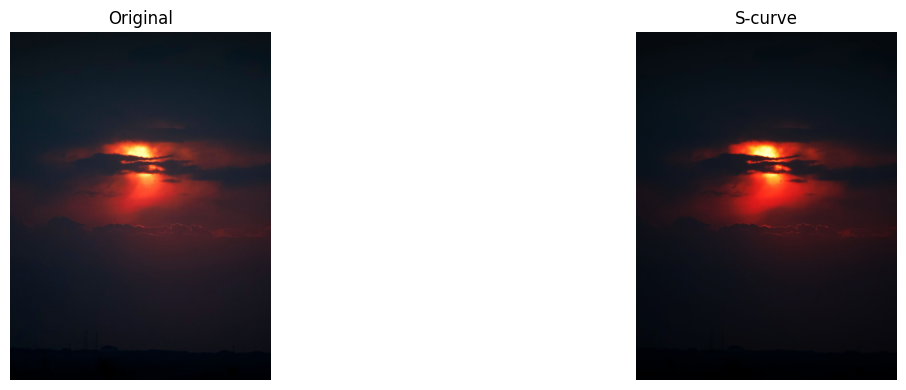

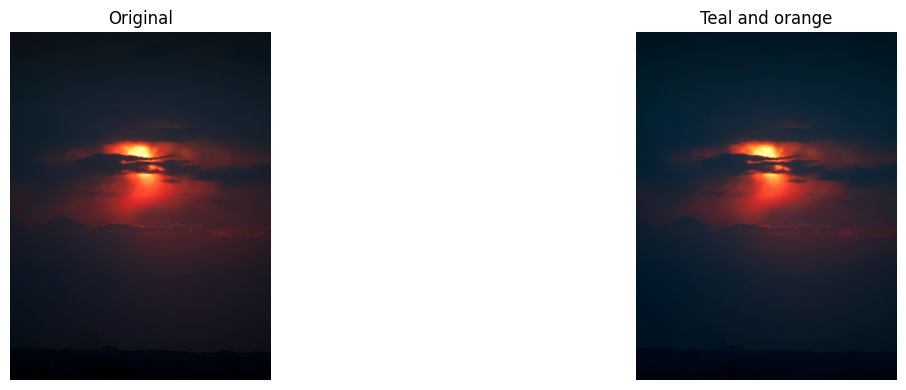

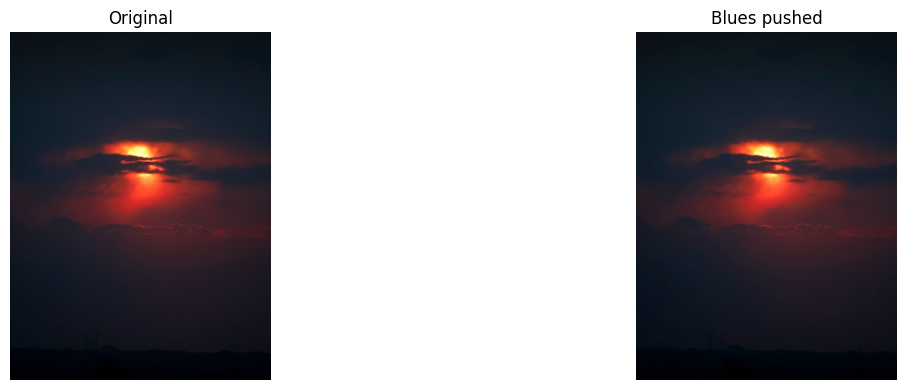

In [21]:
img = small(load_image(files[0]))

# Curves: S-curve
show_many([img, curve(img, [(0, 0), (0.25, 0.18), (0.75, 0.82), (1, 1)])],
          ["Original", "S-curve"])

# Colour wheels: teal shadows, orange highlights
show_many([img, color_wheels(img, shadows=(195, 0.6), highlights=(30, 0.5))],
          ["Original", "Teal and orange"])

# HSL: bluer sky with a slight teal shift
show_many([img, hsl(img, "blue", hue_shift=-15, sat=0.5)],
          ["Original", "Blues pushed"])

In [22]:
def grade(img, exposure_stops=0, contrast_amt=0, saturation_amt=0,
          temp=0, tint_amt=0, shadows_amt=0, highlights_amt=0,
          curve_pts=None, wheels=None, hsl_edits=None, fade_amt=0):
    clamp = lambda v, lo, hi: float(np.clip(v, lo, hi))

    out = exposure(img, clamp(exposure_stops, -3, 3))
    out = temperature(out, clamp(temp, -1, 1))
    out = tint(out, clamp(tint_amt, -1, 1))
    out = contrast(out, clamp(contrast_amt, -1, 1))
    if curve_pts:
        out = curve(out, curve_pts)
    out = shadows(out, clamp(shadows_amt, -1, 1))
    out = highlights(out, clamp(highlights_amt, -1, 1))
    if wheels:
        out = color_wheels(out, **wheels)
    if hsl_edits:
        for e in hsl_edits:
            out = hsl(out, e["color"], clamp(e.get("hue", 0), -30, 30),
                      clamp(e.get("sat", 0), -1, 1), clamp(e.get("lum", 0), -1, 1))
    out = saturation(out, clamp(saturation_amt, -1, 1))
    out = fade(out, clamp(fade_amt, 0, 1))
    return out

In [23]:
PRESETS = {
    "teal_orange": dict(contrast_amt=0.25, saturation_amt=0.05,
                        wheels={"shadows": [195, 0.6], "highlights": [30, 0.5]}),
    "film_fade":   dict(contrast_amt=-0.1, saturation_amt=-0.15, fade_amt=0.5, temp=0.15,
                        curve_pts=[(0, 0), (0.25, 0.22), (0.75, 0.78), (1, 1)]),
    "warm_golden": dict(exposure_stops=0.15, temp=0.45, tint_amt=0.05,
                        shadows_amt=0.2, highlights_amt=-0.2,
                        wheels={"highlights": [40, 0.4]}),
    "cool_moody":  dict(exposure_stops=-0.3, contrast_amt=0.3, saturation_amt=-0.2,
                        temp=-0.5, wheels={"shadows": [215, 0.5]}),
}

def apply_preset(img, name, strength=1.0):
    # strength 0 = original, 1 = full look
    graded = grade(img, **PRESETS[name])
    return np.clip(img + strength * (graded - img), 0, 1)

In [24]:
path = "/content/drive/MyDrive/ai-colorist/presets.json"
with open(path, "w") as f:
    json.dump(PRESETS, f, indent=2)
print("Saved", len(PRESETS), "presets")

Saved 4 presets


In [25]:
@widgets.interact(
    preset=widgets.Dropdown(options=list(PRESETS), description="Look"),
    strength=widgets.FloatSlider(value=1, min=0, max=1, step=0.05,
                                 description="Strength", continuous_update=False),
    split=widgets.FloatSlider(value=0.5, min=0, max=1, step=0.01,
                              description="Split", continuous_update=False))
def preset_viewer(preset, strength, split):
    out = apply_preset(img, preset, strength)
    plt.figure(figsize=(9, 6))
    plt.imshow(np.clip(split_view(img, out, split), 0, 1))
    plt.axis("off")
    plt.show()

interactive(children=(Dropdown(description='Look', options=('teal_orange', 'film_fade', 'warm_golden', 'cool_m…

In [26]:
MODELS = ["gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.5-flash", "gemini-3.1-flash-lite"]

def generate(contents, config=None, tries=3):
    for model in MODELS:
        for attempt in range(tries):
            try:
                reply = client.models.generate_content(
                    model=model, contents=contents, config=config)
                print("(used", model + ")")
                return reply.text or ""
            except Exception as e:
                msg = str(e)
                print(f"{model}, attempt {attempt + 1} failed:", msg[:120])
                if "404" in msg or "NOT_FOUND" in msg:
                    break                          # wrong name: go to the next model
                time.sleep(4 * (attempt + 1))      # wait a bit longer each time
    return ""

print(generate("Say hi in five words."))

(used gemini-3.8-flash)
Hello there, how are you?


In [27]:
# Makes a small preview copy of a photo, so everything runs fast
def small(img, max_side=800):
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1:
        return cv2.resize(img, (int(w * scale), int(h * scale)),
                          interpolation=cv2.INTER_AREA)
    return img

# Check which earlier cells still need to run
needed = ["files", "load_image", "show_many", "luma", "exposure", "contrast",
          "saturation", "temperature", "tint", "shadows", "highlights",
          "curve", "fade", "color_wheels", "hsl", "HUES", "grade",
          "PRESETS", "apply_preset", "split_view", "widgets"]
missing = [n for n in needed if n not in globals()]
print("Missing:", missing if missing else "nothing, all good")

Missing: nothing, all good


In [28]:
def describe_photo(img):
    l = luma(img)[..., 0]
    p5, p50, p95 = np.percentile(l, [5, 50, 95])
    colorful = np.mean(np.max(img, axis=2) - np.min(img, axis=2))
    warmth = np.mean(img[..., 0]) - np.mean(img[..., 2])
    return (f"median brightness {p50:.2f} (0=black, 1=white); darkest 5% at {p5:.2f}; "
            f"brightest 5% at {p95:.2f}; colourfulness {colorful:.2f}; "
            f"warmth {warmth:+.2f} (positive=warm/orange, negative=cool/blue)")

print(describe_photo(small(load_image(files[0]))))

median brightness 0.11 (0=black, 1=white); darkest 5% at 0.01; brightest 5% at 0.23; colourfulness 0.09; warmth +0.00 (positive=warm/orange, negative=cool/blue)


In [29]:
SYSTEM_PROMPT = """You are the brain of an AI colour-grading tool. The user types a request; you reply with a JSON plan that a program applies to the photo. Reply with JSON only: no words before or after it, no code fences.

Format:
{"settings": {...}, "preset": null, "preset_strength": 1.0, "explanation": "one short sentence"}

"settings" may contain only these keys (leave out any you do not need):
- exposure_stops: -3 to 3 (+0.3 is a small brightening)
- contrast_amt: -1 to 1
- saturation_amt: -1 to 1
- temp: -1 to 1 (positive = warmer/orange, negative = cooler/blue)
- tint_amt: -1 to 1 (positive = magenta, negative = green)
- shadows_amt: -1 to 1 (positive lifts dark areas)
- highlights_amt: -1 to 1 (negative recovers bright areas)
- fade_amt: 0 to 1 (lifted blacks, film look)
- curve_pts: list of [input, output] pairs from 0 to 1, e.g. [[0,0],[0.25,0.2],[0.75,0.8],[1,1]]
- wheels: {"shadows": [hue_degrees, strength], "mids": [hue_degrees, strength], "highlights": [hue_degrees, strength]}, strength 0 to 1 (use 0.2 to 0.5)
- hsl_edits: list of {"color": "red|orange|yellow|green|aqua|blue|purple|magenta", "hue": -30 to 30, "sat": -1 to 1, "lum": -1 to 1}

Hue angles: 0 red, 30 orange, 60 yellow, 120 green, 190 teal, 240 blue, 300 magenta.

"preset" is null or one of: PRESET_LIST. Use a preset only when the user asks for that style. preset_strength is 0 to 1.

Rules for good taste:
1. Be subtle. Typical values are 0.1 to 0.35. "A little" = 0.1 to 0.15, normal = 0.2 to 0.35, "a lot" or "very" = 0.4 to 0.6. Never go above 0.6 unless the user clearly asks for an extreme look.
2. Use the photo stats. If the median brightness is above 0.6, brighten less. If it is below 0.35, brighten more. Do not push highlights if the brightest 5% is already above 0.95. Do not add warmth to an already warm photo.
3. Prefer a few settings over many. Do not touch dials the request does not imply.
4. Protect skin tones: no strong saturation boosts on orange, and keep teal in the shadows, not the midtones.
5. If the request is unclear or not about the colour or light of a photo, return {"settings": {}, "preset": null, "preset_strength": 1.0, "explanation": "I could not tell what to change."}
6. If the user asks for one region (sky, face, background), apply a mild global version instead and say in the explanation that region editing is not available yet.
"""
SYSTEM_PROMPT = SYSTEM_PROMPT.replace("PRESET_LIST", ", ".join(PRESETS))

In [30]:
def num(v, lo, hi, default=0.0):
    try:
        return float(np.clip(float(v), lo, hi))
    except (TypeError, ValueError):
        return default

RANGES = {"exposure_stops": (-3, 3), "contrast_amt": (-1, 1), "saturation_amt": (-1, 1),
          "temp": (-1, 1), "tint_amt": (-1, 1), "shadows_amt": (-1, 1),
          "highlights_amt": (-1, 1), "fade_amt": (0, 1)}

def clean_plan(raw):
    settings = {}
    given = raw.get("settings", {})
    if not isinstance(given, dict):
        given = {}
    for key, value in given.items():
        if key in RANGES:
            settings[key] = num(value, *RANGES[key])

        elif key == "curve_pts":
            try:
                pts = {num(a, 0, 1): num(b, 0, 1) for a, b in value}   # removes repeated inputs
                if 2 <= len(pts) <= 8:
                    settings[key] = sorted(pts.items())
            except (TypeError, ValueError):
                pass

        elif key == "wheels" and isinstance(value, dict):
            wheels = {}
            for name in ("shadows", "mids", "highlights"):
                if name in value:
                    try:
                        hue, strength = value[name]
                        wheels[name] = (float(hue) % 360, num(strength, 0, 1))
                    except (TypeError, ValueError):
                        pass
            if wheels:
                settings[key] = wheels

        elif key == "hsl_edits" and isinstance(value, list):
            edits = []
            for e in value[:8]:
                if isinstance(e, dict) and e.get("color") in HUES:
                    edits.append(dict(color=e["color"],
                                      hue=num(e.get("hue", 0), -30, 30),
                                      sat=num(e.get("sat", 0), -1, 1),
                                      lum=num(e.get("lum", 0), -1, 1)))
            if edits:
                settings[key] = edits
        # anything else is ignored

    preset = raw.get("preset")
    if not (isinstance(preset, str) and preset in PRESETS):
        preset = None
    return dict(settings=settings, preset=preset,
                preset_strength=num(raw.get("preset_strength", 1.0), 0, 1, 1.0),
                explanation=str(raw.get("explanation", ""))[:200])

def parse_json(text):
    start, end = text.find("{"), text.rfind("}")      # ignore stray words around the JSON
    if start == -1 or end == -1:
        raise ValueError("no JSON found")
    return json.loads(text[start:end + 1])

(used gemini-3.8-flash)
Brain says: Gently lifted exposure and shadows to brighten the underexposed frame and added a touch of warmth.
Settings: {
 "exposure_stops": 0.35,
 "shadows_amt": 0.25,
 "temp": 0.15
}


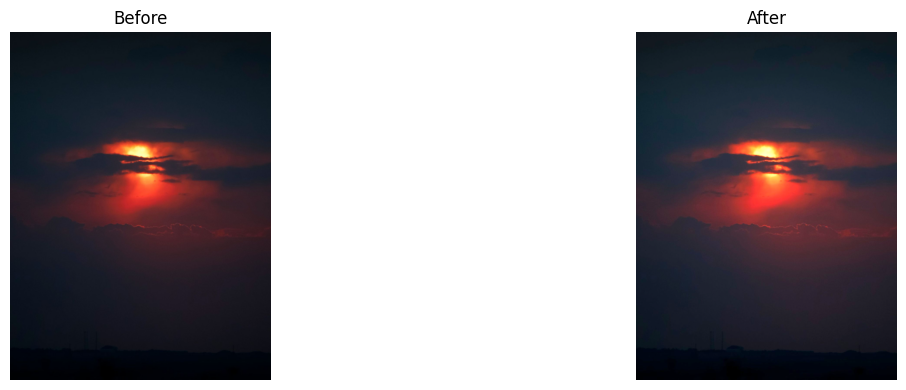

In [33]:
def call_gemini(command, img):
    return generate(
        f"Photo stats: {describe_photo(img)}\nUser request: {command}",
        types.GenerateContentConfig(system_instruction=SYSTEM_PROMPT,
                                    response_mime_type="application/json"))

def ask_brain(command, img):
    text = call_gemini(command, img)
    try:
        return clean_plan(parse_json(text))
    except Exception as e:
        print("Could not read the brain's answer:", e)
        print(text)
        return dict(settings={}, preset=None, preset_strength=1.0,
                    explanation="Could not understand the plan, so the photo is unchanged.")

def run_command(img, command):
    plan = ask_brain(command, img)
    out = img
    if plan["preset"]:
        out = apply_preset(out, plan["preset"], plan["preset_strength"])
    out = grade(out, **plan["settings"])
    print("Brain says:", plan["explanation"])
    print("Settings:", json.dumps(plan["settings"], indent=1))
    return out, plan

# First test
img = small(load_image(files[0]))
out, plan = run_command(img, "make it a little warmer and brighter")
show_many([img, out], ["Before", "After"])

In [32]:
SYSTEM_PROMPT += """
7. Exposure is measured in stops, so use smaller numbers than for other dials: "a little" = 0.1 to 0.25, normal = 0.3 to 0.5, "a lot" = 0.6 to 1.0. On a dark photo, prefer raising shadows_amt over large exposure increases, so the bright parts do not burn out.
"""

In [34]:
cmd_box = widgets.Text(placeholder="Type a command, e.g. make it moody",
                       layout=widgets.Layout(width="520px"))
run_btn = widgets.Button(description="Grade it", button_style="primary")
out_area = widgets.Output()

def on_click(_):
    with out_area:
        out_area.clear_output(wait=True)
        result, plan = run_command(img, cmd_box.value)
        show_many([img, result], ["Before", "After"])

run_btn.on_click(on_click)
display(widgets.VBox([cmd_box, run_btn, out_area]))